# Comparing executed adapters with archived model paths

**Question:** What can a shared final block tell us when statistical and tree adapters run now, while neural and pretrained forecasts come from identified released artifacts?

## Objectives

Compare methods without erasing how their predictions were obtained. This lesson executes the installed AutoETS, AutoTheta, bounded AutoARIMA and LightGBM adapters on one committed history. It also recomputes scores for released neural and pretrained forecast paths using exactly the same future targets. These are two different evidence sources. A freshly executed score on an archived prediction is a new calculation, but it is not a new model fit or a current-checkpoint inference run.

We will examine point error and uncertainty width separately, retain the original forecast names, and identify limitations that a leaderboard cannot resolve. The experiment does not establish performance on a new population, independence from pretraining data or the accuracy of a production planning policy. Its narrower purpose is useful: competitors share their available series, forecast horizon, final targets and scaling rule, so an error difference cannot be attributed to a different scoring block.

## Setup

The exact direct pins below include the actual statistical and tree libraries used in this lesson. The local product adapters specify their settings. Neural and pretrained libraries are not silently installed or replaced by smaller models while the notebook executes.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
```


In [1]:
# Configure a portable lesson session; no data are downloaded.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from chronoscopelab.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from chronoscopelab.model.forecasters import gaussian_quantiles
from chronoscopelab.model.context_memory import fit_context_memory
from chronoscopelab.reevaluation import metrics
from chronoscopelab.engines.statsforecast_engine import StatsforecastForecaster
from chronoscopelab.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0


## Data

Use the generated trend-plus-seasonal case to keep interpretation connected to a visible mechanism. The complete common-holdout artifact additionally contains fifteen selected cases, including four real excerpts. This lesson concentrates on one prefix and its final block so every freshly run adapter has an identical information set. Archived forecasts retain their original inference provenance. The original rolling experiments had unequal origin budgets across methods, which is why their aggregate scores must not be substituted into this common-block comparison.


In [2]:
# The committed trace separates available history from the unseen final block.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print("History:", len(history), "Season:", m, "Holdout:", h)


History: 168 Season: 12 Holdout: 12


## Method

AutoETS selects an exponential-smoothing specification within the installed statsforecast implementation. The adapter receives the seasonal period from the trace and maps the library's analytical interval columns to the requested quantiles. Running the actual adapter matters: a hand-coded smoothing curve with the same display name would not reproduce the library's model selection or parameter fitting. The resulting score applies to this installed version and this history, rather than an unspecified ideal implementation of the ETS family.


In [3]:
# Run the actual installed reference adapter, with the released ETS settings.
ets = StatsforecastForecaster("AutoETS", "ets", max_windows=12)
with warnings.catch_warnings(record=True) as notices:
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    warnings.filterwarnings("ignore", category=SyntaxWarning)
    ets_q = ets.quantiles(history, m, h, (0.1, 0.5, 0.9))
print("AutoETS runtime notices:", [str(w.message) for w in notices])
print("AutoETS MASE:", round(metrics(history, actual, ets_q[:, 1], ets_q[:, 0], ets_q[:, 2], m)["mase"], 4))


AutoETS runtime notices: []
AutoETS MASE: 0.6148


AutoTheta is similarly delegated to the reference library. It is distinct from the local finite-history Theta function introduced earlier. Automatic seasonal treatment and selection can change its forecast, so combining the two under one identity would conceal an implementation choice. The code prints its first prediction to expose an executed result while keeping the same origin and horizon as ETS. Parameter settings are not chosen after looking at the reserved future block.


In [4]:
# AutoTheta is a reference implementation distinct from the local Theta equation.
auto_theta = StatsforecastForecaster("AutoTheta", "theta", max_windows=12)
auto_theta_q = auto_theta.quantiles(history, m, h, (0.1, 0.5, 0.9))
print("AutoTheta first prediction:", round(float(auto_theta_q[0, 1]), 4))


AutoTheta first prediction: 125.8693


AutoARIMA uses the released bounded configuration: stepwise search, approximate fitting and a maximum context of three hundred sixty observations. These choices keep computation practical and are part of the tested method. They do not represent an exhaustive search of all seasonal orders. A stronger or slower alternative would be another experiment with its own runtime and provenance. Numerical runtime notices, including convergence problems, are captured and printed without machine paths. A returned forecast with a convergence notice is not evidence of a successful optimum. Any exception or non-finite output still prevents clean execution.


In [5]:
# Fit the bounded stepwise, approximate AutoARIMA configuration.
arima = StatsforecastForecaster("AutoARIMA", "arima", max_windows=3, ctx_cap=360)
with warnings.catch_warnings(record=True) as notices:
    warnings.simplefilter("always")
    arima_q = arima.quantiles(history, m, h, (0.1, 0.5, 0.9))
print("AutoARIMA runtime notices:", sorted(set(str(w.message) for w in notices)))
print("AutoARIMA first prediction:", round(float(arima_q[0, 1]), 4))


AutoARIMA runtime notices: ['possible convergence problem: minimize gave code 2]']
AutoARIMA first prediction: 117.0052


LightGBM converts past values into lag features and predicts recursively through MLForecast. The configured model uses one hundred trees, thirty-one leaves and a learning rate of five hundredths. Its point objective is not quantile regression. The adapter estimates a residual standard deviation and constructs Gaussian intervals around its point path, so uncertainty is an additional assumption rather than a learned conditional distribution. Recursive reuse of predictions can amplify errors at later leads even when the first-step fit looks convincing.


In [6]:
# Run the point-regression lag-tree adapter, not a quantile-regression substitute.
tree = LightGBMForecaster()
tree_q = tree.quantiles(history, m, h, (0.1, 0.5, 0.9))
print("LightGBM MASE:", round(metrics(history, actual, tree_q[:, 1], tree_q[:, 0], tree_q[:, 2], m)["mase"], 4))


LightGBM MASE: 0.5584


## Comparison

The first figure compares newly executed paths with the same observed final block and a freshly computed SeasonalNaive reference. Every line uses the same value scale. Identify whether the models disagree mainly about trend, recurring shape or amplitude. A model can improve the average while missing the particular peak that matters to a planner. This plot therefore supports diagnosis; the printed scores provide an explicitly defined whole-block comparison without inventing an operational cost function.


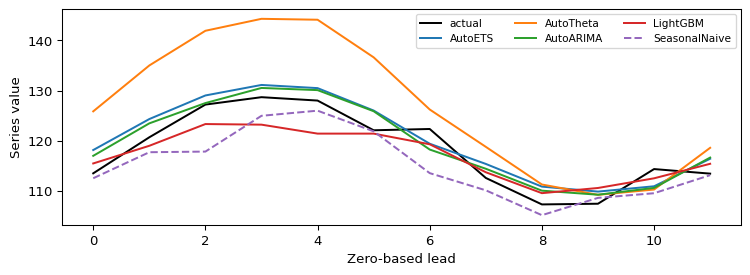

In [7]:
# Compare freshly executed adapters and the historical seasonal reference.
naive, naive_sigma = seasonal_naive(history, m, h)
fig, ax = plt.subplots()
ax.plot(actual, color="black", label="actual")
for label, q in (("AutoETS", ets_q), ("AutoTheta", auto_theta_q), ("AutoARIMA", arima_q), ("LightGBM", tree_q)):
    ax.plot(q[:, 1], label=label)
ax.plot(naive, label="SeasonalNaive", linestyle="--")
ax.set(xlabel="Zero-based lead", ylabel="Series value")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()


The figure makes model disagreement visible but does not attribute its cause uniquely. A difference between a tree and a statistical model can reflect lag features, recursion, context length, fitting objectives or parameter selection. It cannot automatically be called a benefit of model capacity. The common temporal cut removes one confounder while leaving these genuine method differences in place. Controlled ablations would be needed to isolate each proposed explanation.

The next cell uses the frozen neural and pretrained paths stored in the released trace. Direct-torch NLinear, DLinear and NHITS adaptations retain separate names from the neuralforecast variants. Chronos-Bolt, Chronos-2, TimesFM and TiRex paths likewise retain their checkpoint-era provenance. The metric function is executed again on their stored predictions, using the same prefix scale and final targets as the newly executed adapters. No neural training, checkpoint download or foundation-model inference occurs in this cell.


In [8]:
# Recompute scores of released neural and pretrained paths without claiming refits.
frozen = [row for row in trace["methods"] if row["name"] in
          ("NLinear", "DLinear", "NHITS", "NLinear (nf)", "DLinear (nf)", "NHITS (nf)",
           "Chronos-Bolt", "Chronos-2", "TimesFM-2.5", "TiRex-2")]
frozen_scores = [(row["name"], metrics(history, actual, row["point"], row["lower"], row["upper"], m))
                 for row in frozen]
for name, score in frozen_scores:
    print(name, "MASE", round(score["mase"], 4), "coverage", round(score["coverage"], 4))


NHITS (nf) MASE 0.609 coverage 0.4167
DLinear (nf) MASE 2.9511 coverage 0.5833
NLinear (nf) MASE 1.3846 coverage 0.3333
NLinear MASE 0.6563 coverage 0.6667
DLinear MASE 0.3787 coverage 0.5833
NHITS MASE 0.531 coverage 0.4167
Chronos-Bolt MASE 0.7158 coverage 0.5833
Chronos-2 MASE 0.5327 coverage 0.5
TimesFM-2.5 MASE 0.5462 coverage 0.8333
TiRex-2 MASE 0.6389 coverage 0.8333


Point accuracy and interval width answer different questions. The second figure plots MASE against mean width for the archived methods. Coverage remains in the printed table so narrow intervals cannot be praised without checking their misses. Width is expressed in the series' units and should not be pooled directly across unrelated datasets. A low point on this plot is evidence about this block only; it does not prove that a method dominates across repeated origins or costs.


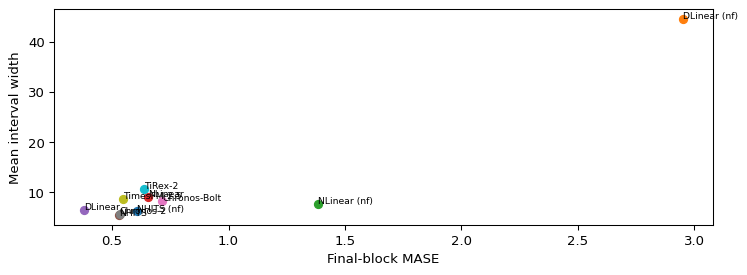

In [9]:
# A score-width view preserves the point/interval tradeoff on this one case.
fig, ax = plt.subplots()
for name, score in frozen_scores:
    ax.scatter(score["mase"], score["mean_width"])
    ax.annotate(name, (score["mase"], score["mean_width"]), fontsize=7)
ax.set(xlabel="Final-block MASE", ylabel="Mean interval width")
fig.tight_layout()
plt.show()


The scatter can expose tradeoffs that disappear in a single ranking. Two models with similar point error can express very different uncertainty, while a broad interval can produce high coverage without useful precision. Three available quantiles also provide a limited view of the predictive distribution. The artifact's weighted quantile loss averages those three quantile scores; it is not an integral over an entire distribution or a claim that every tail probability is reliable.

### Sensitivity to forecast lead

Let $y_1,\ldots,y_n$ be the fitting history and $m$ the declared seasonal lag. The seasonal reference scale uses differences entirely within that prefix.

$$
s_m=\frac{1}{n-m}\sum_{i=m+1}^{n}|y_i-y_{i-m}|.
$$

With the same scale for every method, a group $G$ of forecast leads has scaled absolute error

$$
E_G(f)=\frac{1}{|G|s_m}\sum_{j\in G}|y_{n+j}-\widehat y_{n+j}^{(f)}|.
$$

The full group gives MASE for the reserved block. Split the leads into two equal groups after producing the original fixed-horizon forecasts. The cell below applies the same operation to each newly executed point path and the seasonal reference. It holds the fit, forecast origin, horizon and scale constant. Any change in the relative ordering reflects which outcomes and forecast positions enter the score. A refit at a later origin would expose new information and answer a different question. A change of horizon could also change how an adapter fits or constructs its predictions.


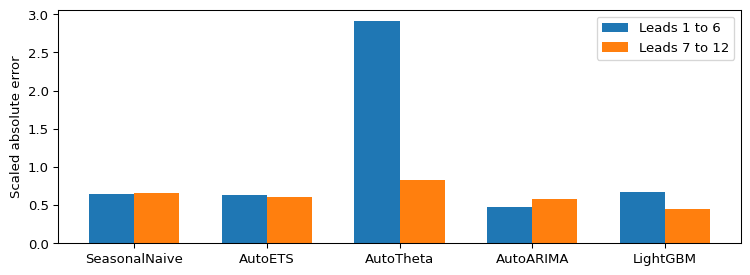

SeasonalNaive early and late [0.6393 0.6535]
AutoETS early and late [0.6287 0.6008]
AutoTheta early and late [2.9087 0.8314]
AutoARIMA early and late [0.4742 0.5784]
LightGBM early and late [0.6729 0.4439]


In [10]:
# Compare early and late errors within one reserved block.
lead_groups = np.array_split(np.arange(h), 2)
scale = np.mean(np.abs(history[m:] - history[:-m]))
paths = {"SeasonalNaive": naive, "AutoETS": ets_q[:, 1], "AutoTheta": auto_theta_q[:, 1],
         "AutoARIMA": arima_q[:, 1], "LightGBM": tree_q[:, 1]}
scores = np.array([[np.mean(np.abs(actual[group] - path[group])) / scale
                    for group in lead_groups] for path in paths.values()])
fig, ax = plt.subplots()
positions = np.arange(len(paths))
for index, group in enumerate(lead_groups):
    ax.bar(positions + (index - 0.5) * 0.34, scores[:, index], width=0.34,
           label=f"Leads {group[0] + 1} to {group[-1] + 1}")
ax.set_xticks(positions, list(paths))
ax.set(ylabel="Scaled absolute error")
ax.legend()
fig.tight_layout()
plt.show()
for name, pair in zip(paths, scores, strict=True):
    print(name, "early and late", np.round(pair, 4))


Read each pair of bars together. Differences in the later leads can reflect recursion, accumulating trend mismatch, or the position of a difficult peak. The plot alone cannot identify which explanation applies. Compare the exact leads in the earlier path plot before making an attribution. The early and late scores are dependent because the forecasts were issued together and the targets come from one series. Repeating the exercise across origins with nonoverlapping target blocks would support stronger evidence. Keep all models' early and late results, including cases where the preferred method changes. A decision that only acts on the next six steps may reasonably emphasize the first group. State that priority before checking the scores.

### Try this with your own data

Choose one regularly sampled series and retain the original timestamps, units and missing-value flags. Decide the forecasting horizon from the action that needs the predictions. Use the actual data frequency to specify a seasonal lag, or declare a one-step scale where seasonality is unsupported. Pick the last training timestamp before reading the reserved values. Save the complete contiguous history, the targets in chronological order and the forecast origin. Check that every method receives that history, that all paths have the same number of leads and that every reported point or quantile uses the original target units.

Inspect the denominator before computing MASE. A constant seasonal recurrence can give zero scale. In that case report the absolute error in source units and declare scaled error undefined. Dropping these cases only for one candidate can produce an apparent advantage by changing the sample. Log exceptions, convergence notices and checkpoint revisions next to the paths. If a pretrained model has an uncertain training-data overlap, retain that uncertainty alongside its scores. Use the same decisions on the next independently reserved blocks before changing the roster. These records let another reader determine whether an apparent improvement belongs to the model, the evaluation design or the data available at the time.

If the target represents energy per interval, sum forecasts across a decision block only after checking the aggregation rule. A sum of marginal lower quantiles generally differs from the lower quantile of the total. For a procurement total, validate the forecast distribution of that total on its own historical decision blocks.

## Results

**Answer:** The fresh and archived paths are evaluated against the same 12 future observations, which supports a direct score comparison on this case. Four statistical/tree adapters execute here. The neural and pretrained entries are rescored frozen paths, so this lesson supplies no new fitting or current-checkpoint evidence for them. Their printed error and coverage values remain useful when interpreted with that provenance.

The number of methods is not the number of independent experimental replications. Their errors share a target series and often share modelling assumptions. General comparisons require declared datasets, multiple temporal origins, appropriate dependence-aware uncertainty and resource budgets. For real excerpts, potential overlap with model pretraining must also be investigated. Those obligations remain visible instead of being replaced by a favorable mean from a selected collection.

## Summary

Specify what ran, what was read, which implementation and settings produced each path, and what observations define every score. Keep direct adaptations distinct from reference-library implementations. Compare point quality with interval width and coverage, and preserve negative outcomes. The next lesson tests a fixed context-dependent combination against two matching-expert ablations, using a criterion declared before examining the final holdouts.

## References

- Forecast scaling: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Local Theta identity: https://robjhyndman.com/papers/Theta.pdf
- Smoothing and seasonal continuation: https://otexts.com/fpp3/holt-winters.html
- Feature-dependent combinations: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Dynamic ensembles: https://doi.org/10.1007/s10994-018-05774-y
